# CS 363M Final Project
Luke Henderson (ldh2674)  
Evan White     (eww495)

## Introduction

Parkinson's disease is a progressive neurodegenerative disorder of the central nervous system that primarily affects movement. It affects approximately 1 million Americans, with common symptoms including tremors, stiffness, and slowed movement. Although there is no cure, medications and deep brain stimulation can manage symptoms. The disease is not typically directly fatal, but complications can be life-threatening. Early diagnosis allows for earlier treatment and improved quality of life.

Clinicians assess disease severity with the Unified Parkinson's Disease Rating Scale. Motor UPDRS measures motor symptoms, and total UPDRS measures overall severity, including motor and non-motor symptoms. Higher scores indicate more severe symptoms. This project predicts total UPDRS from voice measurements so that changes in disease severity can be monitored remotely.

Run this notebook from top to bottom from the repository root. The only data input is `data/parkinsons_updrs.csv`; all project Python, model comparisons, and preprocessing checks used here are defined in the notebook. The follow-up experiments are labeled exploratory because they were developed after the original test results had been inspected.

## Dataset Description

The Parkinson's Telemonitoring Dataset contains 5,875 voice recordings from 42 patients with early-stage Parkinson's disease, collected over a six-month period. Developed by researchers at the University of Oxford in collaboration with 10 U.S. medical centers and Intel, the dataset explores how changes in speech can be used to monitor Parkinson's disease progression remotely.

Each recording contains 16 biomedical voice measurements, along with patient demographics, time since enrollment, Motor_UPDRS, and Total_UPDRS. The prediction target is total UPDRS. It is the broader severity score because it includes motor and non-motor symptoms. Motor UPDRS remains in the dataset for validity checks and is excluded from the predictors.

The features of the dataset are as follows: 
- Subject: Integer that uniquely identifies each subject  
- Age: Subject age  
- Sex: Subject gender ‘0’ - male, ‘1’ - female  
- Test_time: Time since recruitment into the trial. The integer part is the number of days since recruitment  
- Motor_UPDRS: Clinician’s motor UPDRS score, linearly interpolated  
- Total_UPDRS: Clinician’s total UPDRS score, linearly interpolated  
- Jitter (%), Jitter(Abs), Jitter. RAP, Jitter. PPQ5, Jitter. DDP: Several measures of variation in fundamental frequency (Frequency parameters)  
- Shimmer, Shimmer (dB), Shimmer. APQ3, Shimmer. APQ5, Shimmer. APQ11, Shimmer. DDA: Several measures of variation in amplitude (Amplitude parameters)  
- NHR, HNR: Two measures of ratio of noise to tonal components in the voice  
- RPDE: A nonlinear dynamical complexity measure  
- DFA: Signal fractal scaling exponent  
- PPE: A nonlinear measure of fundamental frequency variation  
  
These voice measurements capture variations in pitch, loudness, noise, and vocal stability, which can be affected by Parkinson's disease. By analyzing patterns in these features, we aim to develop models that accurately predict total UPDRS and support noninvasive, remote monitoring of disease severity and progression.

## Data Prep

### Check for missing, infinite, duplicate, and repeated values

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("data/parkinsons_updrs.csv")
repeated_patient_times = df.duplicated(subset=["subject#", "test_time"])

# Check for missing values, infinities, and duplicate rows
print("Missing values:", df.isna().sum().sum())
print("Infinite values:", np.isinf(df).sum().sum())
print(f"Repeated patient/time pairs: {repeated_patient_times.sum():,}")     # multiple recordings that have the same patient and record time as another row (expected, not a problem)
print("Duplicate rows:", df.duplicated().sum())

df.head()

Missing values: 0
Infinite values: 0
Repeated patient/time pairs: 3,374
Duplicate rows: 0
Out[1]: 
   subject#  age  sex  test_time  ...     HNR     RPDE      DFA      PPE
0         1   72    0     5.6431  ...  21.640  0.41888  0.54842  0.16006
1         1   72    0    12.6660  ...  27.183  0.43493  0.56477  0.10810
2         1   72    0    19.6810  ...  23.047  0.46222  0.54405  0.21014
3         1   72    0    25.6470  ...  24.445  0.48730  0.57794  0.33277
4         1   72    0    33.6420  ...  26.126  0.47188  0.56122  0.19361

[5 rows x 22 columns]


The dataset contains no missing values, infinite values, or exact duplicate rows, so no cleaning was necessary. There are 3,374 repeated patient/time pairs, which is expected since patients can have multiple voice recordings at the same recorded time.

### Invalid values check

In [2]:
# Check for invalid or inconsistent values
print("Invalid ages:", ((df["age"] <= 0) | (df["age"] > 120)).sum())
print("Invalid sex values:", (~df["sex"].isin([0, 1])).sum())

print("Negative UPDRS scores:",
      ((df["motor_UPDRS"] < 0) | (df["total_UPDRS"] < 0)).sum())

print("Total UPDRS below motor UPDRS:",
      (df["total_UPDRS"] < df["motor_UPDRS"]).sum())

print("Negative test times:", (df["test_time"] < 0).sum())

Invalid ages: 0
Invalid sex values: 0
Negative UPDRS scores: 0
Total UPDRS below motor UPDRS: 0
Negative test times: 12



All ages, sex values, and UPDRS scores passed the validity checks. There were 12 recordings with negative test times, which may represent measurements taken before the enrollment reference date. Since these are not necessarily errors, we decided to keep them.

### Inspect outliers

In [3]:
continuous = df.drop(columns=["subject#", "sex"])

# Uses Tukeys Fences to detect outliers
q1 = continuous.quantile(0.25)
q3 = continuous.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_flags = (continuous < lower) | (continuous > upper)

outlier_counts = outlier_flags.sum()
outlier_report = pd.DataFrame({
    "lower_fence": lower,
    "upper_fence": upper,
    "outlier_count": outlier_counts,
    "outlier_percent": (outlier_flags.mean() * 100).round(2),
}).sort_values("outlier_count", ascending=False)

display(outlier_report)
print(f"Rows with at least one outlier: {outlier_flags.any(axis=1).sum():,} (all retained)")

Rows with at least one outlier: 931 (all retained)


,lower_fence,upper_fence,outlier_count,outlier_percent
NHR,-0.019807,0.062225,436,7.42
Jitter:PPQ5,-0.000640,0.005920,425,7.23
Jitter:RAP,-0.000985,0.005855,414,7.05
Jitter:DDP,-0.002980,0.017580,413,7.03
Jitter(%),-0.001250,0.011630,398,6.77
Jitter(Abs),-0.000024,0.000100,366,6.23
Shimmer,-0.011825,0.070695,333,5.67
Shimmer(dB),-0.110000,0.650000,332,5.65
Shimmer:APQ3,-0.007663,0.037518,332,5.65
Shimmer:DDA,-0.023027,0.112592,331,5.63


Using Tukey's fences (1.5 × IQR), 931 recordings were flagged as having at least one outlier. Most outliers occurred in the NHR, Jitter, and Shimmer measurements, with roughly 5–7% of values flagged for several of these features. Since extreme voice measurements could reflect genuine differences in Parkinson's symptoms, I decided not to remove any observations.

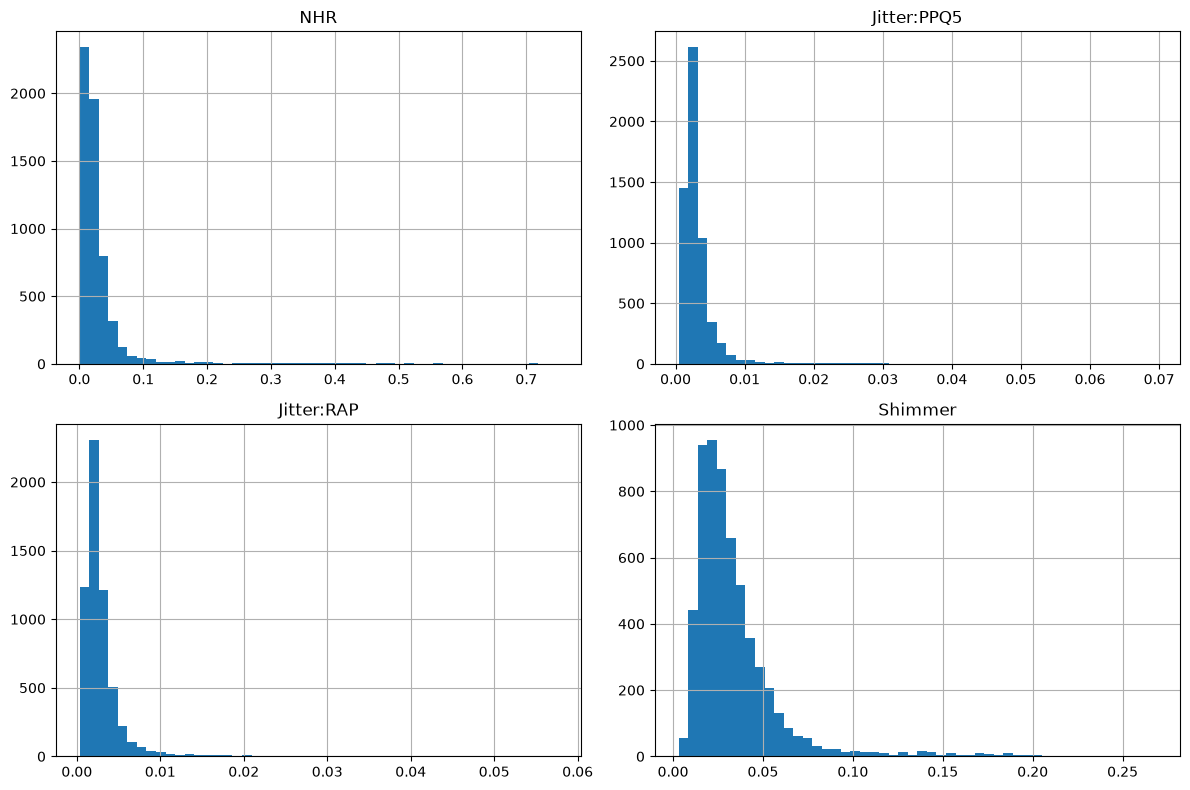

In [4]:
import matplotlib.pyplot as plt

features = ["NHR", "Jitter:PPQ5", "Jitter:RAP", "Shimmer"]

df[features].hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

The histograms show that NHR, Jitter, and Shimmer are strongly right-skewed, with most measurements concentrated at lower values and a relatively small number extending much higher. This explains why the IQR method identified so many outliers. The extreme values appear to be part of long-tailed distributions rather than obvious data errors, so I will retain them for modeling and consider transformations if needed.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, test_idx = next(splitter.split(df, groups=df["subject#"]))

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

print("Training recordings:", len(train))
print("Testing recordings:", len(test))
print("Training patients:", train["subject#"].nunique())
print("Testing patients:", test["subject#"].nunique())

Training recordings: 4640
Testing recordings: 1235
Training patients: 33
Testing patients: 9


## Data Exploration

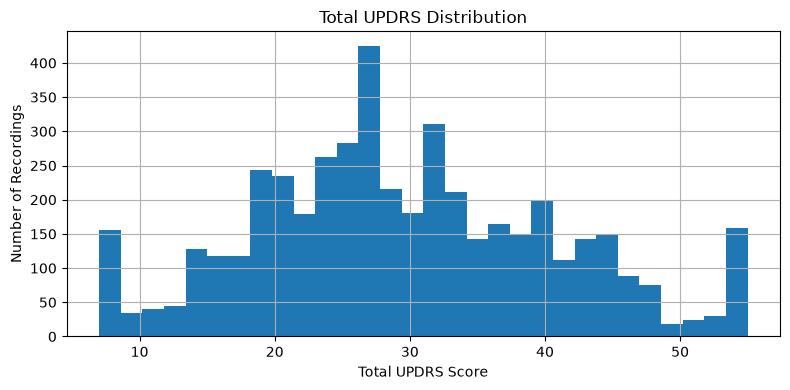

,total_UPDRS
count,4640.000000
mean,29.565597
std,11.022521
min,7.000000
25%,21.715000
50%,28.115500
75%,37.236250
max,54.992000


In [6]:
import matplotlib.pyplot as plt

target = "total_UPDRS"

ax = train[[target]].hist(bins=30, figsize=(8, 4)).flat[0]
ax.set_title("Total UPDRS Distribution")
ax.set_xlabel("Total UPDRS Score")
ax.set_ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

display(train[[target]].describe())

The training set contains 4,640 recordings. Total UPDRS ranges from 7.00 to 54.99 and is concentrated around scores of 20–35. The distribution is not strongly skewed, although it has several peaks, which may reflect differences in disease severity between patients. Because the target already covers a broad range of scores, I don't see an immediate need to transform it.

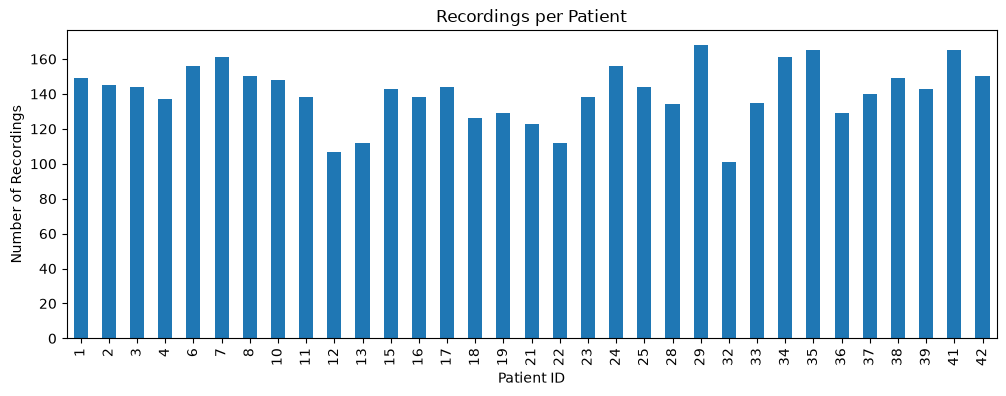

count     33.000000
mean     140.606061
std       16.695694
min      101.000000
25%      134.000000
50%      143.000000
75%      150.000000
max      168.000000
dtype: float64

In [7]:
recordings = train.groupby("subject#").size()

recordings.plot(kind="bar", figsize=(12, 4))
plt.title("Recordings per Patient")
plt.xlabel("Patient ID")
plt.ylabel("Number of Recordings")
plt.show()

display(recordings.describe())

Recording counts range from 101 to 168 and are relatively consistent across patients. Since no patient contributes substantially more recordings than the others, we do not see a need to rebalance or weight the observations by patient.

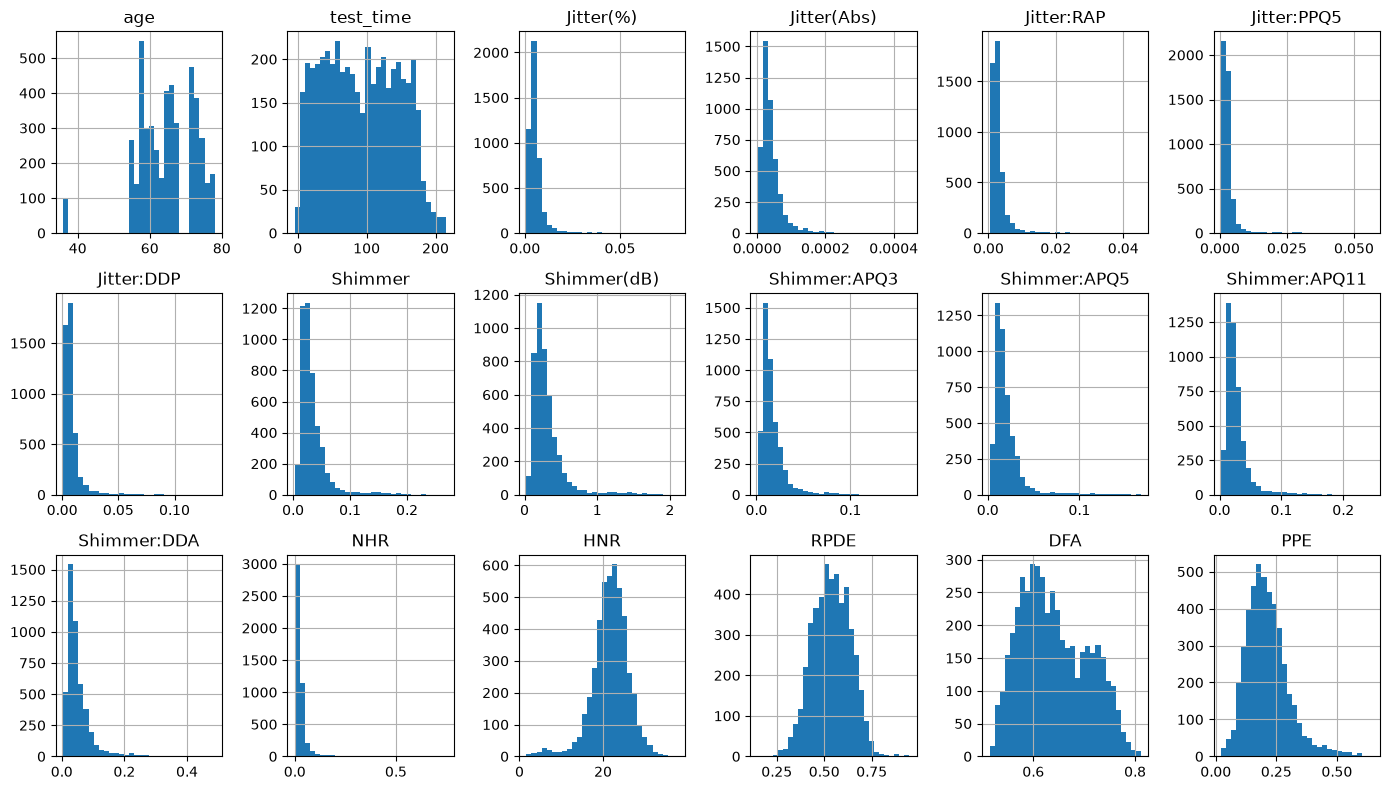

Jitter:PPQ5      6.492170
NHR              6.125149
Jitter:DDP       5.551170
Jitter:RAP       5.551042
Jitter(%)        5.264114
Shimmer:APQ5     3.822463
Jitter(Abs)      3.475975
Shimmer:APQ11    3.434173
Shimmer          3.397594
Shimmer:APQ3     3.205556
Shimmer:DDA      3.205552
Shimmer(dB)      3.181388
PPE              1.102557
DFA              0.330821
test_time        0.086193
RPDE             0.012532
age             -0.781646
HNR             -0.875499
dtype: float64

In [8]:
features = train.drop(
    columns=["subject#", "sex", "motor_UPDRS", "total_UPDRS"]
).columns

train[features].hist(bins=30, figsize=(14, 8), layout=(3, 6))
plt.tight_layout()
plt.show()

display(train[features].skew().sort_values(ascending=False))

Most of the jitter and shimmer measurements, along with NHR, are strongly right-skewed, while HNR and RPDE have more symmetric distributions. The features also vary considerably in scale so we will consider log transformations for highly skewed features and standardization for models sensitive to feature scale such as KNN.

Jitter(%) & Jitter(Abs): 0.9189
Jitter(%) & Jitter:RAP: 0.9843
Jitter(%) & Jitter:PPQ5: 0.9675
Jitter(%) & Jitter:DDP: 0.9843
Jitter(Abs) & Jitter:RAP: 0.9039
Jitter(Abs) & Jitter:DDP: 0.9039
Jitter:RAP & Jitter:PPQ5: 0.9420
Jitter:RAP & Jitter:DDP: 1.0000
Jitter:PPQ5 & Jitter:DDP: 0.9420
Jitter:PPQ5 & NHR: 0.9026
Shimmer & Shimmer(dB): 0.9934
Shimmer & Shimmer:APQ3: 0.9812
Shimmer & Shimmer:APQ5: 0.9841
Shimmer & Shimmer:APQ11: 0.9442
Shimmer & Shimmer:DDA: 0.9812
Shimmer(dB) & Shimmer:APQ3: 0.9711
Shimmer(dB) & Shimmer:APQ5: 0.9768
Shimmer(dB) & Shimmer:APQ11: 0.9450
Shimmer(dB) & Shimmer:DDA: 0.9711
Shimmer:APQ3 & Shimmer:APQ5: 0.9631
Shimmer:APQ3 & Shimmer:APQ11: 0.9024
Shimmer:APQ3 & Shimmer:DDA: 1.0000
Shimmer:APQ5 & Shimmer:APQ11: 0.9478
Shimmer:APQ5 & Shimmer:DDA: 0.9631
Shimmer:APQ11 & Shimmer:DDA: 0.9024


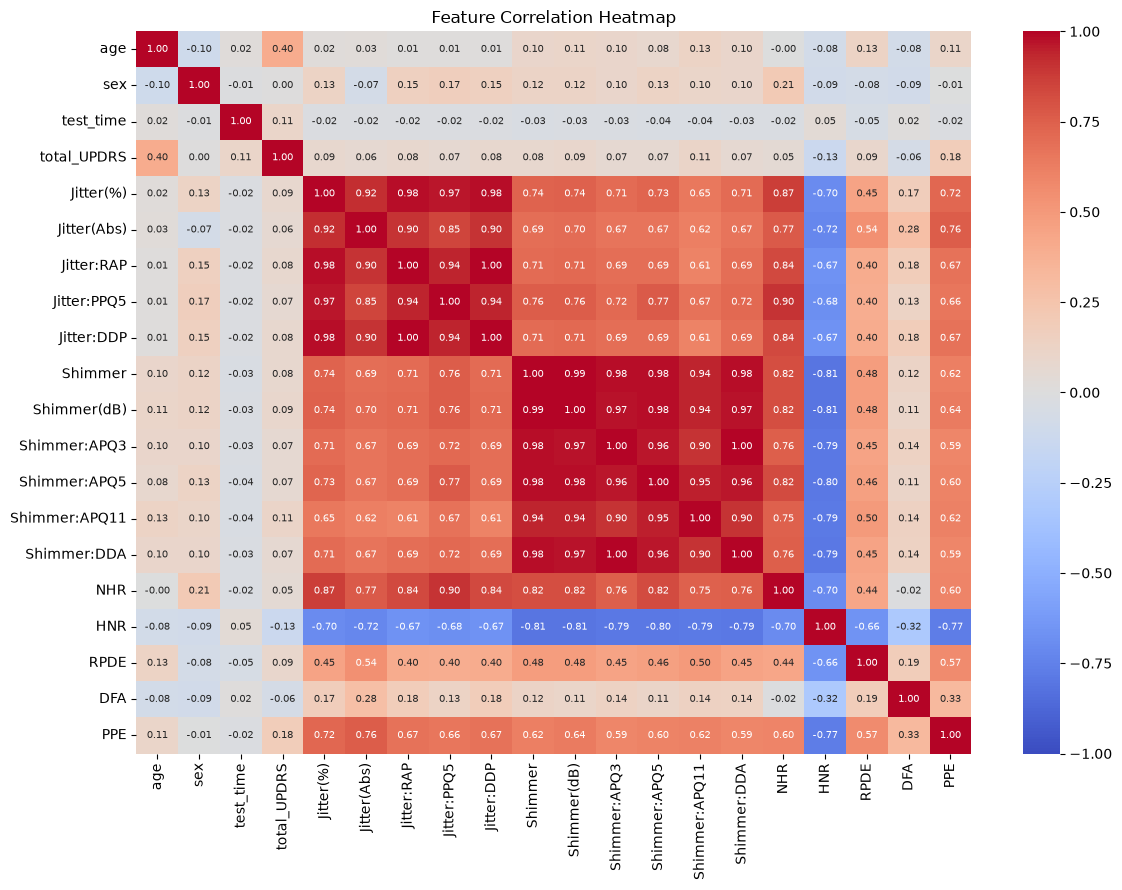

In [9]:
import seaborn as sns

correlation = train.drop(columns=["subject#", "motor_UPDRS"]).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


feature_corr = train[features].corr()

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        corr = feature_corr.iloc[i, j]

        if abs(corr) >= 0.9:
            print(f"{features[i]} & {features[j]}: {corr:.4f}")

Most of the Jitter measurements are highly correlated with each other, and the same is true for Shimmer. We could combine these measurements into one feature for Jitter and one for Shimmer instead of using each measurement individually. Age has the strongest correlation with total UPDRS. Since the voice measurements have weak linear correlations with the target, we also want to test nonlinear models such as decision trees, neural nets, and KNN.

In [10]:
target_corr = correlation.loc[features, "total_UPDRS"]

display(target_corr.sort_values(key=abs, ascending=False))

age              0.401549
PPE              0.182730
HNR             -0.128897
Shimmer:APQ11    0.110255
test_time        0.105407
RPDE             0.089096
Shimmer(dB)      0.086736
Jitter(%)        0.085094
Jitter:DDP       0.079721
Jitter:RAP       0.079706
Shimmer          0.078839
Shimmer:APQ5     0.069368
Jitter:PPQ5      0.067484
Shimmer:DDA      0.065429
Shimmer:APQ3     0.065426
Jitter(Abs)      0.064836
DFA             -0.064137
NHR              0.048002
Name: total_UPDRS, dtype: float64

Age has the strongest correlation with total UPDRS, followed by PPE. Most of the other features have correlations below 0.1 in magnitude. Since no individual feature has a strong linear relationship with the target, we are going to see how well these features work together and whether nonlinear models perform better.

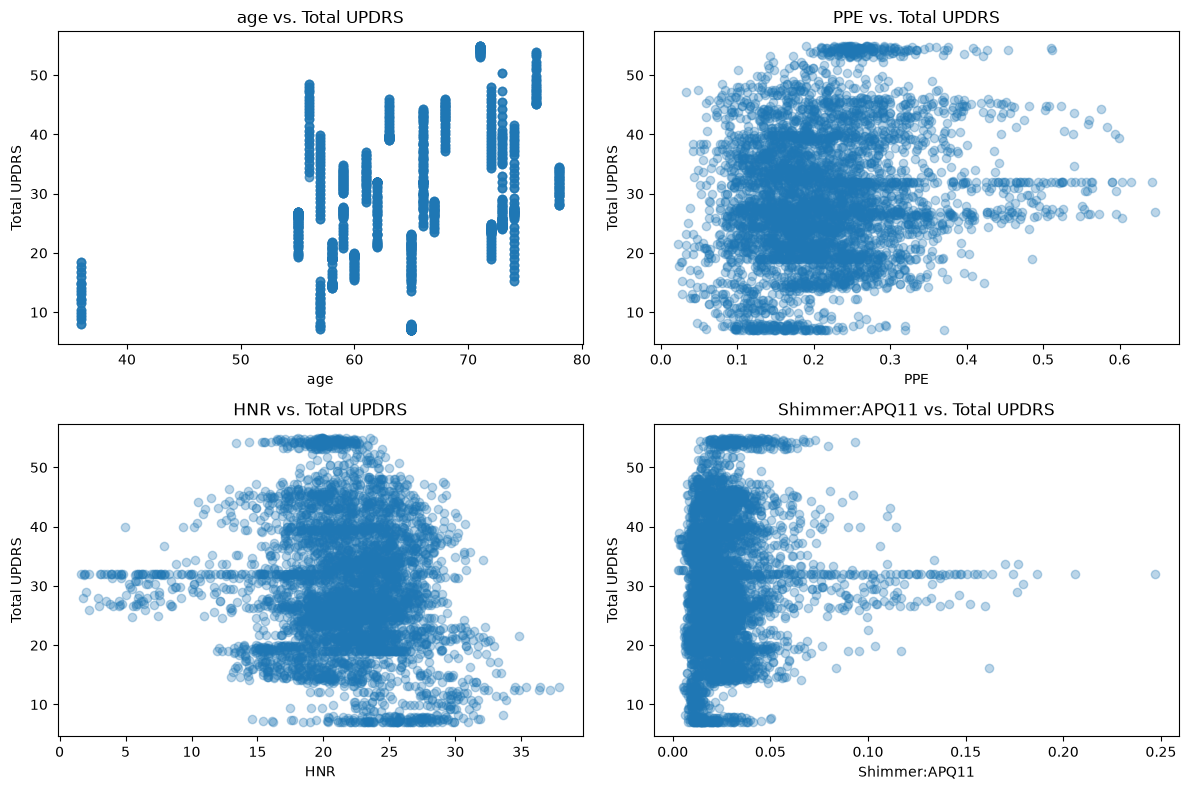

In [11]:
selected = target_corr.abs().nlargest(4).index

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected, axes.flat):
    ax.scatter(train[feature], train["total_UPDRS"], alpha=0.3)
    ax.set_xlabel(feature)
    ax.set_ylabel("Total UPDRS")
    ax.set_title(f"{feature} vs. Total UPDRS")

plt.tight_layout()
plt.show()

Age shows the clearest relationship with total UPDRS, with older patients generally having higher scores. The other three features are much more scattered and do not show clear linear trends. This makes it difficult to predict UPDRS from any single voice measurement, so again, this leads us to test how well the features work together in both linear and nonlinear models.

## Feature Engineering

### Compare log transformations

The Jitter, Shimmer, and NHR measurements were strongly right-skewed during exploration. We originally attempted to transform these features with a `log1p(x)` method, but found that it barely reduced skew. We then tested the natural log `log(x)` which effectively reduced the skew of the features. We compare their training-set skewness before transformation and after each transformation where values closer to zero indicate less skew.

In [12]:
X_train_raw = train.drop(columns=["subject#", "motor_UPDRS", "total_UPDRS"]).copy()
X_test_raw = test.drop(columns=["subject#", "motor_UPDRS", "total_UPDRS"]).copy()
y_train = train["total_UPDRS"].copy()
y_test = test["total_UPDRS"].copy()

jitter_cols = [col for col in X_train_raw if col.startswith("Jitter")]
shimmer_cols = [col for col in X_train_raw if col.startswith("Shimmer")]
log_cols = jitter_cols + shimmer_cols + ["NHR"]

if (X_train_raw[log_cols] <= 0).any().any():
    raise ValueError("Natural logs require strictly positive measurements.")

# Compare both methods on the same training measurements.
X_train_log1p = X_train_raw.copy()
X_train_log1p[log_cols] = np.log1p(X_train_raw[log_cols])
X_train_log = X_train_raw.copy()
X_train_log[log_cols] = np.log(X_train_raw[log_cols])

skew_comparison = pd.DataFrame({
    "Original": X_train_raw[log_cols].skew(),
    "Our first method: log1p(x)": X_train_log1p[log_cols].skew(),
    "Natural log: log(x)": X_train_log[log_cols].skew(),
})
skew_comparison.index.name = "Feature"
display(skew_comparison.round(3))

,Original,Our first method: log1p(x),Natural log: log(x)
Feature,,,
Jitter(%),5.264,5.156,0.936
Jitter(Abs),3.476,3.475,0.151
Jitter:RAP,5.551,5.477,0.845
Jitter:PPQ5,6.492,6.412,1.186
Jitter:DDP,5.551,5.340,0.845
Shimmer,3.398,3.194,0.592
Shimmer(dB),3.181,2.238,0.563
Shimmer:APQ3,3.206,3.076,0.390
Shimmer:APQ5,3.822,3.657,0.555


We chose the natural log because it reduced skewness much more than `log1p` for these small positive measurements—for example, NHR skewness fell from 6.13 to 0.39 with `log`, compared with 5.45 with `log1p`.

In [13]:
X_train = X_train_log.copy()
X_test = X_test_raw.copy()
if (X_test[log_cols] <= 0).any().any():
    raise ValueError("Natural logs require strictly positive test measurements.")
X_test[log_cols] = np.log(X_test[log_cols])

### Combine Jitter and Shimmer

Our earlier correlation analysis showed that the Jitter measurements are highly correlated with one another, as are the Shimmer measurements To reduce the dimensionality of our data we standardize and average the measurements within each group to create `Jitter_combined` and `Shimmer_combined` features, then remove the individual measurements.

In [14]:
from sklearn.preprocessing import StandardScaler

jitter_cols = [col for col in X_train.columns if col.startswith("Jitter")]
shimmer_cols = [col for col in X_train.columns if col.startswith("Shimmer")]

jitter_scaler = StandardScaler()
shimmer_scaler = StandardScaler()

X_train["Jitter_combined"] = jitter_scaler.fit_transform(
    X_train[jitter_cols]
).mean(axis=1)

X_test["Jitter_combined"] = jitter_scaler.transform(
    X_test[jitter_cols]
).mean(axis=1)

X_train["Shimmer_combined"] = shimmer_scaler.fit_transform(
    X_train[shimmer_cols]
).mean(axis=1)

X_test["Shimmer_combined"] = shimmer_scaler.transform(
    X_test[shimmer_cols]
).mean(axis=1)

In [15]:
X_train_reduced = X_train.drop(columns=jitter_cols + shimmer_cols)
X_test_reduced = X_test.drop(columns=jitter_cols + shimmer_cols)

print("Reduced feature count:", X_train_reduced.shape[1])

Reduced feature count: 10


### Combined feature preview

The 10-feature tables `X_train_reduced` and `X_test_reduced` retain combined Jitter/Shimmer measurements and natural-log NHR. They illustrate the preprocessing. The modeling pipelines below rebuild these transformations and fit their scalers inside each training fold. The following subsection defines two additional baseline-change features for a separate 12-feature comparison.

In [16]:
groups_train = train.loc[X_train_reduced.index, "subject#"].copy()
groups_test = test.loc[X_test_reduced.index, "subject#"].copy()

assert set(groups_train).isdisjoint(groups_test)
assert X_train_reduced.index.equals(y_train.index)
assert X_test_reduced.index.equals(y_test.index)
assert X_train_reduced.columns.equals(X_test_reduced.columns)
assert np.isfinite(X_train_reduced.to_numpy()).all()
assert np.isfinite(X_test_reduced.to_numpy()).all()

print("Training features:", X_train_reduced.shape)
print("Test features:", X_test_reduced.shape)
with pd.option_context("display.max_columns", None):
    display(X_train_reduced.head())

Training features: (4640, 10)
Test features: (1235, 10)


,age,sex,test_time,NHR,HNR,RPDE,DFA,PPE,Jitter_combined,Shimmer_combined
0,72,0,5.6431,-4.248195,21.640,0.41888,0.54842,0.16006,0.545527,-0.205583
1,72,0,12.6660,-4.499730,27.183,0.43493,0.56477,0.10810,-0.939698,-0.598572
2,72,0,19.6810,-3.901083,23.047,0.46222,0.54405,0.21014,-0.250397,-0.924606
3,72,0,25.6470,-3.581389,24.445,0.48730,0.57794,0.33277,-0.158478,-0.236045
4,72,0,33.6420,-4.454597,26.126,0.47188,0.56122,0.19361,-1.123416,-0.878356


### Changes from each patient's baseline voice

**Hypothesis:** A patient's voice changes may help estimate current total UPDRS beyond the existing voice levels and demographics. We add exactly two predictors:

- `Jitter_change_from_baseline`: current-session mean combined jitter minus first-session mean combined jitter.
- `Shimmer_change_from_baseline`: current-session mean combined shimmer minus first-session mean combined shimmer.

A session means all recordings with the same `subject#` and `test_time`. Combining those recordings avoids using an arbitrary previous row as a reference. Both new predictors are zero in the first session. Later values describe cumulative change, rather than change since the immediately preceding session.

We still train one regression across multiple patients. The target is the current total UPDRS score; neither an initial UPDRS score nor previous UPDRS scores are inputs. This is estimation with voice history available, rather than future-score forecasting. Predictions assume the current recording session is complete.

The transformer below is defined here so the notebook needs only the dataset and installed libraries. Its `fit` method learns component scales from training patients; its `transform` method creates the combined features and session changes.


In [17]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_is_fitted


class BaselineVoiceFeatures(TransformerMixin, BaseEstimator):
    """Combine logged voice measures and optionally add two baseline changes.

    Input is a DataFrame containing subject#, test_time, and raw predictors.
    Each transform call must include each patient's history starting at their
    first recording session. Predictions are made after the current session is
    complete; recordings at identical patient/time values form one session.
    No future sessions or UPDRS labels are needed to calculate an earlier row.

    Component scalers are learned in fit. Patient baselines are calculated from
    the supplied voice history in transform, including for previously unseen
    patients. subject# is used only for grouping and never returned as a feature.
    """

    def __init__(self, include_changes=True):
        self.include_changes = include_changes

    @staticmethod
    def _validate_frame(X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Voice history must be a pandas DataFrame.")
        if not {"subject#", "test_time"}.issubset(X.columns):
            raise ValueError("Voice history requires subject# and test_time.")
        if {"motor_UPDRS", "total_UPDRS"}.intersection(X.columns):
            raise ValueError("Exclude UPDRS labels from voice history.")
        if not np.isfinite(X.to_numpy(dtype=float)).all():
            raise ValueError("Voice history must contain finite numeric values.")

    def _logged(self, X):
        result = X.copy()
        if (result[self.log_columns_] <= 0).any().any():
            raise ValueError("Logged voice measurements must be positive.")
        result[self.log_columns_] = np.log(result[self.log_columns_])
        return result

    def fit(self, X, y=None):
        self._validate_frame(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        self.jitter_columns_ = [c for c in X if c.startswith("Jitter")]
        self.shimmer_columns_ = [c for c in X if c.startswith("Shimmer")]
        if not self.jitter_columns_ or not self.shimmer_columns_:
            raise ValueError("Raw jitter and shimmer measurements are required.")
        self.log_columns_ = self.jitter_columns_ + self.shimmer_columns_ + ["NHR"]
        self.other_columns_ = [
            c for c in X
            if c not in self.jitter_columns_ + self.shimmer_columns_ + ["subject#"]
        ]
        logged = self._logged(X)
        self.jitter_scaler_ = StandardScaler().fit(logged[self.jitter_columns_])
        self.shimmer_scaler_ = StandardScaler().fit(logged[self.shimmer_columns_])
        return self

    def transform(self, X):
        check_is_fitted(self, "jitter_scaler_")
        self._validate_frame(X)
        if list(X.columns) != list(self.feature_names_in_):
            raise ValueError("Use the same input columns and order as in fit.")
        logged = self._logged(X)
        result = logged[self.other_columns_].copy()
        combined_columns = ["Jitter_combined", "Shimmer_combined"]
        result[combined_columns[0]] = self.jitter_scaler_.transform(
            logged[self.jitter_columns_]
        ).mean(axis=1)
        result[combined_columns[1]] = self.shimmer_scaler_.transform(
            logged[self.shimmer_columns_]
        ).mean(axis=1)

        if self.include_changes:
            # Aggregate only recordings sharing the same patient and time.
            sessions = result[combined_columns].copy()
            sessions["subject#"] = X["subject#"].to_numpy()
            sessions["test_time"] = X["test_time"].to_numpy()
            sessions = sessions.groupby(["subject#", "test_time"], sort=True)[
                combined_columns
            ].mean()
            first_sessions = sessions.groupby(level="subject#").head(1)
            baselines = first_sessions.droplevel("test_time")
            row_sessions = pd.MultiIndex.from_frame(X[["subject#", "test_time"]])
            changes = (
                sessions.reindex(row_sessions).to_numpy()
                - baselines.reindex(X["subject#"].to_numpy()).to_numpy()
            )
            result[["Jitter_change_from_baseline", "Shimmer_change_from_baseline"]] = changes
        return result

In [18]:
import matplotlib.pyplot as plt

# Keep the subject ID only so the transformer can find each patient's sessions.
# The transformer removes it before the regression sees the feature table.
X_voice_history = train.drop(columns=["motor_UPDRS", "total_UPDRS"]).copy()
assert X_voice_history.index.equals(y_train.index)
assert X_voice_history["subject#"].equals(groups_train)

# Preview on training patients only. Evaluation below fits fresh transformers.
voice_preview_transformer = BaselineVoiceFeatures()
voice_preview = voice_preview_transformer.fit_transform(X_voice_history)
change_columns = ["Jitter_change_from_baseline", "Shimmer_change_from_baseline"]
first_session = X_voice_history["test_time"].eq(
    X_voice_history.groupby("subject#")["test_time"].transform("min")
)
assert (voice_preview.loc[first_session, change_columns] == 0).all().all()
assert "subject#" not in voice_preview
assert voice_preview.shape[1] == 12

print("Original combined features: 10; with baseline changes:", voice_preview.shape[1])
with pd.option_context("display.max_columns", None):
    display(pd.concat([
        X_voice_history[["subject#", "test_time"]],
        voice_preview[["Jitter_combined", "Shimmer_combined"] + change_columns],
    ], axis=1).head(12).round(3))

Original combined features: 10; with baseline changes: 12


,subject#,test_time,Jitter_combined,Shimmer_combined,Jitter_change_from_baseline,Shimmer_change_from_baseline
0,1,5.643,0.546,-0.206,0.000,0.000
1,1,12.666,-0.940,-0.599,-0.716,0.389
2,1,19.681,-0.250,-0.925,-0.027,0.063
3,1,25.647,-0.158,-0.236,-0.162,0.276
4,1,33.642,-1.123,-0.878,-0.900,0.109
5,1,40.652,-0.834,-0.364,-0.433,0.575
6,1,47.649,-0.262,0.825,0.673,1.233
7,1,54.640,-0.115,-0.412,0.296,0.522
8,1,61.669,-0.426,0.550,-0.199,1.016
9,1,68.688,0.006,0.410,0.074,1.350


## Modeling: Predicting total_UPDRS

### Initial model comparison

We first compare constant baselines, ordinary linear regression, KNN, trees, and a neural network. Follow-up sections then examine the two temporal features and regularization using training patients only.

In [19]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

folds = list(GroupKFold(5).split(X_train_raw, y_train, groups_train))
scores, model_specs = {}, {}
selected_parameters = {}
print("Training patients:", groups_train.nunique())
print("Outer validation folds:", len(folds))

Training patients: 33
Outer validation folds: 5


Each patient has many recordings, so splitting individual rows could let a model learn from the same patients it is evaluated on. We keep patients together and use the same five outer folds for every model. Three inner folds choose model settings using only the outer training patients, keeping the outer validation patients separate from tuning.

In [20]:
# Recreate our feature engineering inside each training fold.
def log_voice(X):
    X = X.copy()
    X[log_cols] = np.log(X[log_cols])
    return X


def average_columns(X):
    return np.asarray(X).mean(axis=1, keepdims=True)


def feature_steps(version="combined"):
    log = FunctionTransformer(log_voice) if version in ["logged", "combined"] else "passthrough"
    columns = "passthrough"
    if version == "combined":
        combine = Pipeline([
            ("scale", StandardScaler()),
            ("average", FunctionTransformer(average_columns)),
        ])
        other = [c for c in X_train_raw if c not in jitter_cols + shimmer_cols]
        columns = ColumnTransformer([
            ("other", "passthrough", other),
            ("jitter", clone(combine), jitter_cols),
            ("shimmer", clone(combine), shimmer_cols),
        ])
    elif version == "demographics":
        columns = ColumnTransformer([
            ("demographics", "passthrough", ["age", "sex", "test_time"])
        ])
    return Pipeline([("log", log), ("columns", columns)])

The skewness and correlation plots motivated our log transformation and combined Jitter/Shimmer features. We compare the original, logged, combined, and demographics-only inputs to check whether these choices improve prediction. The component scalers and final scaler are fitted again inside each training fold so validation patients do not influence preprocessing.

In [21]:
# evaluation loop
def evaluate(name, model, grid=None, version="combined", scale=True):
    pipe = Pipeline([
        ("features", feature_steps(version)),
        ("scale", StandardScaler() if scale else "passthrough"),
        ("model", model),
    ])
    model_specs[name] = (pipe, grid or {})
    rows = []
    selected_parameters[name] = []
    for fold, (a, b) in enumerate(folds, start=1):
        X_fit, X_val = X_train_raw.iloc[a], X_train_raw.iloc[b]
        y_fit, y_val = y_train.iloc[a], y_train.iloc[b]
        inner = list(GroupKFold(3).split(X_fit, y_fit, groups_train.iloc[a]))
        search = GridSearchCV(pipe, grid or {}, cv=inner,
                              scoring="neg_mean_absolute_error", error_score="raise")
        search.fit(X_fit, y_fit)
        for parameter, value in search.best_params_.items():
            selected_parameters[name].append({
                "Model": name, "Parameter": parameter.split("__")[-1],
                "Values tried": str(grid[parameter]),
                "Fold": fold, "Selected": str(value),
            })
        prediction = search.predict(X_val)
        rows.append({
            "Train MAE": mean_absolute_error(y_fit, search.predict(X_fit)),
            "CV MAE": mean_absolute_error(y_val, prediction),
            "CV RMSE": root_mean_squared_error(y_val, prediction),
            "CV R²": r2_score(y_val, prediction),
        })
    folds_table = pd.DataFrame(rows)
    scores[name] = folds_table.mean().to_dict()
    scores[name]["MAE fold SD"] = folds_table["CV MAE"].std()
    display(pd.DataFrame([scores[name]], index=[name]).round(3))

We use MAE as the main metric because it measures how many UPDRS points our predictions are off by, with RMSE highlighting larger errors and R² providing another performance measure. Comparing training and validation error helps us see whether a model fits known patients better than new ones. The fold standard deviation shows how much results change with the validation patients; it is not a confidence interval.

In [22]:
# Establish baselines and test our feature choices with linear regression.
evaluate("Mean baseline", DummyRegressor(), version="raw", scale=False)
evaluate("Median baseline", DummyRegressor(strategy="median"), version="raw", scale=False)

for version in ["raw", "logged", "combined", "demographics"]:
    evaluate(f"Linear / {version}", LinearRegression(), version=version)

display(pd.DataFrame(scores).T.sort_values("CV MAE").round(3))

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Mean baseline,8.879,8.971,10.977,-0.234,2.158


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Median baseline,8.811,9.036,11.029,-0.232,2.207


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / raw,7.887,9.651,11.357,-0.376,1.374


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / logged,7.722,9.881,11.65,-0.473,1.187


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / combined,7.913,9.352,11.021,-0.232,1.91


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / demographics,8.303,8.832,10.448,-0.152,1.723


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / demographics,8.303,8.832,10.448,-0.152,1.723
Mean baseline,8.879,8.971,10.977,-0.234,2.158
Median baseline,8.811,9.036,11.029,-0.232,2.207
Linear / combined,7.913,9.352,11.021,-0.232,1.910
Linear / raw,7.887,9.651,11.357,-0.376,1.374
Linear / logged,7.722,9.881,11.650,-0.473,1.187


We start with constant predictions to check whether using the features helps at all. The median is a useful baseline because it minimizes absolute error on the training data, although this does not guarantee the lowest validation error. Since age had the strongest correlation with UPDRS, demographics alone tests whether voice adds information beyond age, sex, and recording time.

The mean and median baselines had CV MAE 8.971 and 9.036. Logging alone increased linear regression's MAE from 9.651 to 9.881, while combining the logged measurements reduced it to 9.352. Demographics alone performed better at 8.832. Reducing skew and redundancy helped relative to the raw-feature regression, but the combined voice model still did not beat either constant baseline.

In [23]:
# Test whether similar recordings have similar UPDRS scores.
evaluate("KNN", KNeighborsRegressor(), {
    "model__n_neighbors": [15, 50, 150],
    "model__weights": ["uniform", "distance"],
})

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
KNN,6.679,10.102,11.988,-0.401,2.886


Because the voice measurements had weak individual linear relationships with UPDRS, we test whether nearby recordings in feature space have similar scores using KNN. We vary the number of neighbors and their weighting to compare local predictions with smoother ones, with scaling fitted inside each fold.

KNN had training MAE 6.679 but CV MAE 10.102, compared with 9.352 for combined-feature linear regression. Its closer fit to training recordings did not improve predictions for new patients.

In [24]:
# Compare a single tree with an ensemble of trees.
evaluate("Decision tree", DecisionTreeRegressor(random_state=42), {
    "model__max_depth": [2, 4, 8],
    "model__min_samples_leaf": [20, 100],
}, scale=False)

evaluate("Random forest", RandomForestRegressor(n_estimators=100, random_state=42), {
    "model__max_depth": [4, None],
    "model__min_samples_leaf": [20, 100],
}, scale=False)

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Decision tree,7.177,10.163,12.017,-0.601,1.804


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Random forest,4.627,12.6,14.624,-1.389,2.23


Decision trees can model thresholds and interactions that a linear model may miss. We limit depth and require larger leaves to reduce memorization, then average 100 trees in a random forest to test whether an ensemble generalizes better.

The tree had CV MAE 10.163 and the forest 12.600. Although the forest fit training data more closely (MAE 4.627 versus 7.177), it performed worse on validation patients. Averaging trees did not resolve the generalization problem in this experiment.

In [25]:
# Test nonlinear relationships with a small neural network.
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

neural_net = TransformedTargetRegressor(
    regressor=MLPRegressor(
        hidden_layer_sizes=(8,), activation="tanh", solver="lbfgs",
        alpha=1, max_iter=3000, max_fun=100000, random_state=42,
    ),
    transformer=StandardScaler(),
)
evaluate("Neural network", neural_net, {
    "model__regressor__hidden_layer_sizes": [(8,), (16,)],
    "model__regressor__alpha": [1, 100],
})

,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Neural network,6.75,10.166,12.146,-0.476,2.442


Weak linear correlations do not rule out nonlinear relationships, so we test a neural network with a tanh activation function. We use one hidden layer with 8 or 16 neurons and compare two regularization strengths to limit complexity with only 33 training patients. Inputs and target scores are scaled within the training folds, and predictions are converted back to UPDRS points before evaluation.

The network had training MAE 6.750 and CV MAE 10.166, compared with 9.352 for combined-feature linear regression. It fit the training data more closely without improving predictions for new patients.

In [26]:
# Show what each inner search selected for its outer training fold.
tuning = pd.DataFrame([
    row for rows in selected_parameters.values() for row in rows
])
tuning_table = tuning.pivot(
    index=["Model", "Parameter", "Values tried"],
    columns="Fold", values="Selected",
).rename(columns=lambda fold: f"Fold {fold}")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(tuning_table)

Fold                                                        Fold 1   Fold 2  \
Model          Parameter          Values tried                                
Decision tree  max_depth          [2, 4, 8]                      2        2   
               min_samples_leaf   [20, 100]                     20      100   
KNN            n_neighbors        [15, 50, 150]                150      150   
               weights            ['uniform', 'distance']  uniform  uniform   
Neural network alpha              [1, 100]                     100      100   
               hidden_layer_sizes [(8,), (16,)]               (8,)    (16,)   
Random forest  max_depth          [4, None]                      4     None   
               min_samples_leaf   [20, 100]                     20      100   

Fold                                                        Fold 3   Fold 4  \
Model          Parameter          Values tried                                
Decision tree  max_depth          [2, 4, 8]                      2        2   
               min_samples_leaf   [20, 100]                     20       20   
KNN            n_neighbors        [15, 50, 150]                150      150   
               weights            ['uniform', 'distance']  uniform  uniform   
Neural network alpha              [1, 100]                     100      100   
               hidden_layer_sizes [(8,), (16,)]               (8,)     (8,)   
Random forest  max_depth          [4, None]                   None     None   
               min_samples_leaf   [20, 100]                    100      100   

Fold                                                        Fold 5  
Model          Parameter          Values tried                      
Decision tree  max_depth          [2, 4, 8]                      2  
               min_samples_leaf   [20, 100]                     20  
KNN            n_neighbors        [15, 50, 150]                150  
               weights            ['uniform', 'distance']  uniform  
Neural network alpha              [1, 100]                     100  
               hidden_layer_sizes [(8,), (16,)]              (16,)  
Random forest  max_depth          [4, None]                   None  
               min_samples_leaf   [20, 100]                    100

We tune these settings to test how much complexity the data can support when predicting scores for new patients. The table records what each outer training subset selected using only its inner validation folds. The large training–validation gaps show that these searches did not remove overfitting. With only 33 training patients, choices that work for one set of patients may not transfer consistently to another.

Selected by validation MAE: Linear / demographics


,Train MAE,CV MAE,CV RMSE,CV R²,MAE fold SD
Linear / demographics,8.303,8.832,10.448,-0.152,1.723
Mean baseline,8.879,8.971,10.977,-0.234,2.158
Median baseline,8.811,9.036,11.029,-0.232,2.207
Linear / combined,7.913,9.352,11.021,-0.232,1.910
Linear / raw,7.887,9.651,11.357,-0.376,1.374
Linear / logged,7.722,9.881,11.650,-0.473,1.187
KNN,6.679,10.102,11.988,-0.401,2.886
Decision tree,7.177,10.163,12.017,-0.601,1.804
Neural network,6.750,10.166,12.146,-0.476,2.442
Random forest,4.627,12.600,14.624,-1.389,2.230


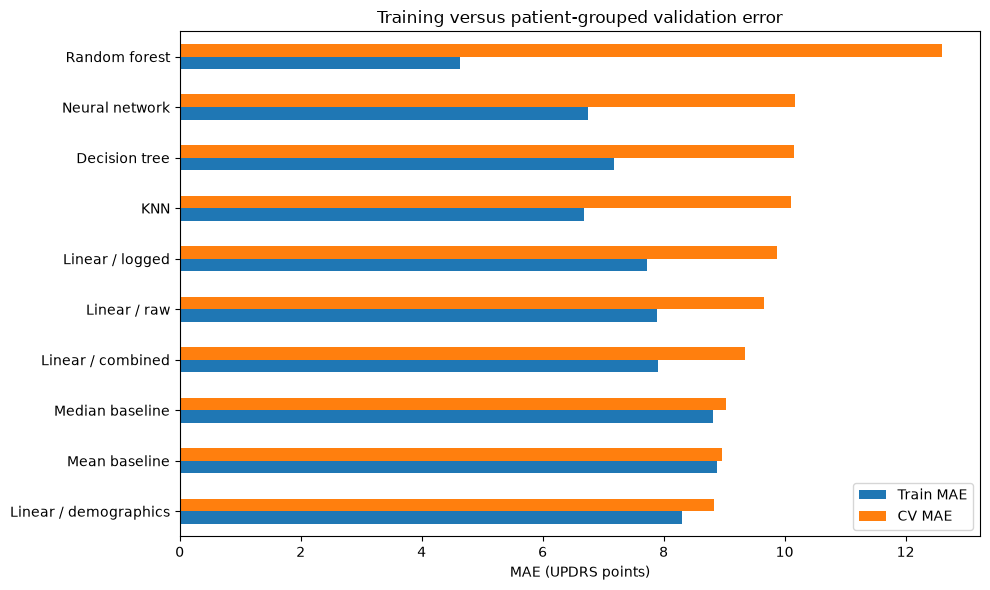

In [27]:
# Compare validation performance and training–validation gaps.
comparison = pd.DataFrame(scores).T.sort_values("CV MAE")
display(comparison.round(3))

comparison[["Train MAE", "CV MAE"]].plot.barh(figsize=(10, 6))
plt.xlabel("MAE (UPDRS points)")
plt.title("Training versus patient-grouped validation error")
plt.tight_layout()
plt.show()

winner = comparison.index[0]
print("Selected by validation MAE:", winner)

Among the initial models, linear regression using only age, sex, and recording time had the lowest CV MAE at 8.832, compared with 8.971 for the better constant baseline (the mean). This improvement was small relative to variation across patient groups. Adding voice features did not improve validation performance, even after logging and combining related measurements. More complex models had larger training–validation gaps.

The next sections test whether changes relative to each patient's baseline voice, or stronger control of coefficient sizes, can improve on this initial result.

### Testing the baseline-change hypothesis (exploratory)

The transformer logs and combines the same jitter and shimmer measurements as the original pipeline. Component scalers are fitted only on the training patients in each fold, and the two changes use those same scales. No patient ID is passed to the regressor.

For validation patients, baseline voice measurements come from their own first recording session. Earlier sessions do not use later sessions or severity labels. Each transform call must include the patient's history starting at that first session; an isolated later recording would lose the baseline reference.

We compare the original 10 combined features with the same features plus the two changes, using the same linear regression and five patient-grouped folds. Demographics-only regression and constant baselines provide context. No parameters are tuned in this first comparison. These follow-ups were proposed after the original test results were inspected, so they are exploratory training-set analyses. They do not evaluate the nine test patients.

In [28]:
# Separate variables preserve the original model comparison and final results.
voice_change_specs = {
    "Mean baseline": Pipeline([("model", DummyRegressor())]),
    "Median baseline": Pipeline([("model", DummyRegressor(strategy="median"))]),
    "Linear / demographics": Pipeline([
        ("select", ColumnTransformer([
            ("demographics", "passthrough", ["age", "sex", "test_time"]),
        ])),
        ("scale", StandardScaler()),
        ("model", LinearRegression()),
    ]),
}
for label, include_changes in [
    ("Linear / combined", False),
    ("Linear / combined + baseline changes", True),
]:
    voice_change_specs[label] = Pipeline([
        ("features", BaselineVoiceFeatures(include_changes=include_changes)),
        ("scale", StandardScaler()),
        ("model", LinearRegression()),
    ])

voice_change_rows = []
for name, pipeline in voice_change_specs.items():
    for fold, (a, b) in enumerate(folds, start=1):
        assert set(groups_train.iloc[a]).isdisjoint(groups_train.iloc[b])
        fitted = clone(pipeline).fit(X_voice_history.iloc[a], y_train.iloc[a])
        prediction = fitted.predict(X_voice_history.iloc[b])
        fold_patient_errors = pd.DataFrame({
            "patient": groups_train.iloc[b].to_numpy(),
            "absolute_error": np.abs(y_train.iloc[b].to_numpy() - prediction),
        }).groupby("patient")["absolute_error"].mean()
        voice_change_rows.append({
            "Model": name, "Fold": fold,
            "Train MAE": mean_absolute_error(y_train.iloc[a], fitted.predict(X_voice_history.iloc[a])),
            "CV MAE": mean_absolute_error(y_train.iloc[b], prediction),
            "CV RMSE": root_mean_squared_error(y_train.iloc[b], prediction),
            "CV R²": r2_score(y_train.iloc[b], prediction),
            "Equal-patient MAE": fold_patient_errors.mean(),
        })

voice_change_fold_scores = pd.DataFrame(voice_change_rows)
voice_change_comparison = voice_change_fold_scores.groupby("Model", sort=False)[
    ["Train MAE", "CV MAE", "CV RMSE", "CV R²", "Equal-patient MAE"]
].mean()
voice_change_comparison["MAE fold SD"] = voice_change_fold_scores.groupby("Model")["CV MAE"].std()
with pd.option_context("display.max_columns", None):
    display(voice_change_comparison.sort_values("CV MAE").round(3))

,Train MAE,CV MAE,CV RMSE,CV R²,Equal-patient MAE,MAE fold SD
Model,,,,,,
Linear / demographics,8.303,8.832,10.448,-0.152,8.684,1.723
Mean baseline,8.879,8.971,10.977,-0.234,8.989,2.158
Median baseline,8.811,9.036,11.029,-0.232,9.009,2.207
Linear / combined,7.913,9.352,11.021,-0.232,9.200,1.910
Linear / combined + baseline changes,7.525,9.458,11.397,-0.378,9.306,1.750


Average MAE gain: -0.107
Validation folds improved: 2 of 5


Model,Linear / combined,Linear / combined + baseline changes,MAE gain from changes
Fold,,,
1,6.323,6.839,-0.516
2,9.127,8.560,0.567
3,11.177,11.187,-0.010
4,9.352,10.366,-1.015
5,10.780,10.339,0.441


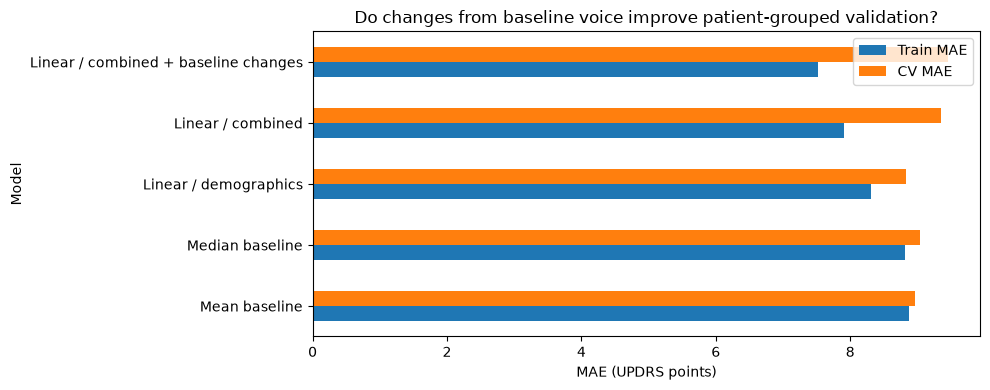

In [29]:
# Pair the same validation folds: positive gain means the two changes helped.
voice_change_paired = voice_change_fold_scores.pivot(index="Fold", columns="Model", values="CV MAE")[
    ["Linear / combined", "Linear / combined + baseline changes"]
].copy()
voice_change_paired["MAE gain from changes"] = (
    voice_change_paired["Linear / combined"]
    - voice_change_paired["Linear / combined + baseline changes"]
)
display(voice_change_paired.round(3))
print("Average MAE gain:", round(voice_change_paired["MAE gain from changes"].mean(), 3))
print("Validation folds improved:", int((voice_change_paired["MAE gain from changes"] > 0).sum()), "of", len(folds))

voice_change_comparison[["Train MAE", "CV MAE"]].plot.barh(figsize=(10, 4))
plt.xlabel("MAE (UPDRS points)")
plt.title("Do changes from baseline voice improve patient-grouped validation?")
plt.tight_layout()
plt.show()

#### What the change features added

In this run, adding the two baseline-change features increased mean validation MAE from **9.352 to 9.458** (about **0.107 points worse**, using unrounded values). They improved MAE in **2 of 5** patient folds. Training MAE decreased from **7.913 to 7.525**, while equal-patient validation MAE also worsened from **9.200 to 9.306**. For this linear model and these folds, the two features did not support our hypothesis. This does not rule out all uses of voice history.

We judge the two new predictors by their paired validation MAE differences against the original combined-feature regression, and by whether they help consistently across patient folds. Demographics and constant baselines help assess whether any improvement is practically useful. The equal-patient metric is averaged within each fold, and the fold standard deviation is descriptive rather than a confidence interval.

This experiment uses an initial voice session, not an initial clinical score. Even a positive result would support only current-score estimation with a voice history in this cohort. The small patient sample and interpolated UPDRS labels remain limitations; independent patients with directly measured follow-up scores would be needed to validate a monitoring system.

### Regularization and absolute-error loss (exploratory)

The baseline-change features increased linear regression's validation error, so we test whether constraining model complexity helps. Ridge shrinks coefficients, while Lasso can set coefficients to zero. Median regression and absolute-error gradient boosting more directly target absolute error.

The search compares demographics, combined voice features, and combined voice features plus the two changes. Hyperparameters are selected in three inner patient-grouped folds, and all models are evaluated on the same five outer folds as before. We also record each recipe's default settings. Fixed `Lasso(alpha=1)` rows expose the already evaluated default Lasso results; they are not another parameter search.

Only the 33 training patients are used. This is exploratory model development after the original test results were inspected. Selecting the best of these candidates on cross-validation does not provide an independent estimate of its final performance.

In [30]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Lasso, LinearRegression, QuantileRegressor, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler



def candidate_models():
    """Fix the candidate list and grids before inspecting validation results.

    Ridge/Lasso constrain coefficient sizes; median regression and boosting
    optimize absolute error. All feature preprocessing is fitted within folds.
    """
    recipes = {
        "Linear": (LinearRegression(), {}),
        "Ridge": (Ridge(), {"model__alpha": [1, 100, 10000]}),
        "Lasso": (Lasso(max_iter=20000), {"model__alpha": [0.1, 1, 10]}),
        # Expose the default setting separately; its outer MAE is already
        # measured in each searched Lasso recipe's untuned comparison.
        "Lasso (alpha=1)": (Lasso(alpha=1, max_iter=20000), {}),
        "Median regression": (
            QuantileRegressor(quantile=0.5, solver="highs"),
            {"model__alpha": [0.01, 0.1, 1]},
        ),
    }
    candidates = {}
    for representation in ["demographics", "combined", "combined + baseline changes"]:
        features = (
            ColumnTransformer([
                ("demographics", "passthrough", ["age", "sex", "test_time"])
            ])
            if representation == "demographics"
            else BaselineVoiceFeatures(include_changes="changes" in representation)
        )
        for name, (model, grid) in recipes.items():
            candidates[f"{name} / {representation}"] = (
                Pipeline([
                    ("features", clone(features)),
                    ("scale", StandardScaler()),
                    ("model", clone(model)),
                ]),
                grid,
            )

    for name, strategy in [("Mean baseline", "mean"), ("Median baseline", "median")]:
        candidates[name] = (Pipeline([("model", DummyRegressor(strategy=strategy))]), {})

    # One constrained nonlinear alternative using the two new predictors.
    candidates["Absolute-error boosting / combined + baseline changes"] = (
        Pipeline([
            ("features", BaselineVoiceFeatures()),
            ("model", HistGradientBoostingRegressor(
                loss="absolute_error", learning_rate=0.05, max_iter=100,
                min_samples_leaf=100, l2_regularization=10,
                early_stopping=False, random_state=42,
            )),
        ]),
        {"model__max_leaf_nodes": [3, 7]},
    )
    return candidates

In [31]:
def compare_mae_models(X, y, groups, outer_folds=None, candidates=None):
    """Tune in three inner patient folds and evaluate on five outer folds.

    Pass training patients only. The same outer folds are used for all models.
    Returned fold scores include untuned MAE, parameters, and held-out patients
    so the comparison can be checked without rerunning the searches.
    """
    if not X.index.equals(y.index) or not X.index.equals(groups.index):
        raise ValueError("Predictors, outcomes, and patient groups must align.")
    if not X["subject#"].equals(groups):
        raise ValueError("The subject column must match the validation groups.")
    if outer_folds is None:
        outer_folds = list(GroupKFold(5).split(X, y, groups))
    else:
        outer_folds = list(outer_folds)
    validation_positions = np.concatenate([b for _, b in outer_folds])
    if not np.array_equal(np.sort(validation_positions), np.arange(len(X))):
        raise ValueError("Every recording must be validated exactly once.")

    rows = []
    specs = candidate_models() if candidates is None else candidates
    for name, (pipeline, grid) in specs.items():
        for fold, (a, b) in enumerate(outer_folds, start=1):
            X_fit, X_val = X.iloc[a], X.iloc[b]
            y_fit, y_val = y.iloc[a], y.iloc[b]
            fit_groups, val_groups = groups.iloc[a], groups.iloc[b]
            assert set(fit_groups).isdisjoint(val_groups)
            inner = list(GroupKFold(3).split(X_fit, y_fit, fit_groups))
            for inner_a, inner_b in inner:
                assert set(fit_groups.iloc[inner_a]).isdisjoint(fit_groups.iloc[inner_b])
            search = GridSearchCV(
                clone(pipeline), grid, cv=inner, scoring="neg_mean_absolute_error",
                n_jobs=1, error_score="raise",
            ).fit(X_fit, y_fit)
            prediction = search.predict(X_val)
            untuned = (
                clone(pipeline).fit(X_fit, y_fit).predict(X_val)
                if grid else prediction
            )
            patient_errors = pd.DataFrame({
                "patient": val_groups.to_numpy(),
                "error": np.abs(y_val.to_numpy() - prediction),
            }).groupby("patient")["error"].mean()
            rows.append({
                "Model": name, "Fold": fold,
                "Train MAE": mean_absolute_error(y_fit, search.predict(X_fit)),
                "Untuned CV MAE": mean_absolute_error(y_val, untuned),
                "CV MAE": mean_absolute_error(y_val, prediction),
                "CV RMSE": root_mean_squared_error(y_val, prediction),
                "CV R2": r2_score(y_val, prediction),
                "Equal-patient MAE": patient_errors.mean(),
                "Best parameters": str(search.best_params_),
                "Tuning": "Inner grouped CV" if grid else "Fixed settings",
                "Validation patients": ",".join(map(str, sorted(set(val_groups)))),
            })
        print(f"{name}: CV MAE {np.mean([r['CV MAE'] for r in rows if r['Model'] == name]):.3f}", flush=True)

    fold_scores = pd.DataFrame(rows)
    return summarize_mae_scores(fold_scores), fold_scores


def summarize_mae_scores(fold_scores):
    """Summarize saved outer-fold results without fitting or selecting again."""
    comparison = fold_scores.groupby("Model", sort=False)[[
        "Train MAE", "Untuned CV MAE", "CV MAE", "CV RMSE", "CV R2", "Equal-patient MAE",
    ]].mean()
    comparison["MAE fold SD"] = fold_scores.groupby("Model")["CV MAE"].std()
    comparison["MAE tuning gain"] = comparison["Untuned CV MAE"] - comparison["CV MAE"]
    reference = (
        comparison.loc["Linear / demographics", "CV MAE"]
        if "Linear / demographics" in comparison.index else np.nan
    )
    comparison["MAE gain vs demographics linear"] = reference - comparison["CV MAE"]
    return comparison.sort_values("CV MAE")

In [32]:
# Recompute from training patients; no cached results or helper files are needed.
mae_comparison, mae_fold_scores = compare_mae_models(
    X_voice_history, y_train, groups_train, outer_folds=folds,
)
with pd.option_context("display.max_columns", None, "display.max_colwidth", 65):
    display(mae_comparison[[
        "Train MAE", "CV MAE", "CV RMSE", "CV R2", "MAE fold SD", "MAE tuning gain",
    ]].round(3))

Linear / demographics: CV MAE 8.832
Ridge / demographics: CV MAE 9.123
Lasso / demographics: CV MAE 9.062
Lasso (alpha=1) / demographics: CV MAE 8.632
Median regression / demographics: CV MAE 9.313
Linear / combined: CV MAE 9.352
Ridge / combined: CV MAE 8.850
Lasso / combined: CV MAE 9.207
Lasso (alpha=1) / combined: CV MAE 8.651
Median regression / combined: CV MAE 8.897
Linear / combined + baseline changes: CV MAE 9.458
Ridge / combined + baseline changes: CV MAE 8.823
Lasso / combined + baseline changes: CV MAE 9.179
Lasso (alpha=1) / combined + baseline changes: CV MAE 8.660
Median regression / combined + baseline changes: CV MAE 8.965
Mean baseline: CV MAE 8.971
Median baseline: CV MAE 9.036
Absolute-error boosting / combined + baseline changes: CV MAE 10.353


,Train MAE,CV MAE,CV RMSE,CV R2,MAE fold SD,MAE tuning gain
Model,,,,,,
Lasso (alpha=1) / demographics,8.244,8.632,10.315,-0.096,1.816,0.000
Lasso (alpha=1) / combined,8.131,8.651,10.371,-0.099,1.835,0.000
Lasso (alpha=1) / combined + baseline changes,7.965,8.660,10.333,-0.096,1.701,0.000
Ridge / combined + baseline changes,8.340,8.823,10.648,-0.161,1.915,0.634
Linear / demographics,8.303,8.832,10.448,-0.152,1.723,0.000
Ridge / combined,8.447,8.850,10.688,-0.166,1.950,0.501
Median regression / combined,8.689,8.897,10.823,-0.188,2.146,0.139
Median regression / combined + baseline changes,8.731,8.965,10.969,-0.222,2.143,0.070
Mean baseline,8.879,8.971,10.977,-0.234,2.158,0.000


In [33]:
# Compare the fixed-setting candidates on exactly the same validation patients.
mae_paired = mae_fold_scores.pivot(index="Fold", columns="Model", values="CV MAE")
mae_fixed_comparison = mae_paired[[
    "Linear / demographics", "Lasso (alpha=1) / demographics",
    "Linear / combined + baseline changes",
    "Lasso (alpha=1) / combined + baseline changes",
]].copy()
mae_fixed_comparison["Lasso gain on same 12 features"] = (
    mae_fixed_comparison["Linear / combined + baseline changes"]
    - mae_fixed_comparison["Lasso (alpha=1) / combined + baseline changes"]
)
with pd.option_context("display.max_columns", None):
    display(mae_fixed_comparison.round(3))
print("Folds improved by regularizing the 12-feature model:",
      int((mae_fixed_comparison["Lasso gain on same 12 features"] > 0).sum()), "of", len(folds))

# Negative tuning gain in the full table means the search hurt outer MAE.
display(mae_comparison.loc[
    ["Lasso / demographics", "Lasso / combined", "Lasso / combined + baseline changes"],
    ["Untuned CV MAE", "CV MAE", "MAE tuning gain"],
].round(3))

Folds improved by regularizing the 12-feature model: 4 of 5


Model,Linear / demographics,Lasso (alpha=1) / demographics,Linear / combined + baseline changes,Lasso (alpha=1) / combined + baseline changes,Lasso gain on same 12 features
Fold,,,,,
1,6.468,5.870,6.839,5.852,0.987
2,9.068,9.579,8.560,9.478,-0.918
3,9.876,9.925,11.187,9.868,1.320
4,7.865,7.698,10.366,8.260,2.106
5,10.884,10.090,10.339,9.845,0.494


,Untuned CV MAE,CV MAE,MAE tuning gain
Model,,,
Lasso / demographics,8.632,9.062,-0.430
Lasso / combined,8.651,9.207,-0.556
Lasso / combined + baseline changes,8.660,9.179,-0.519


In [34]:
# Fit the three fixed Lasso candidates on training patients to inspect coefficients.
# These fitted objects can estimate scores; they are not evaluated on test labels.

mae_fixed_models = {}
mae_coefficient_rows = []
for name, (pipeline, _) in candidate_models().items():
    if not name.startswith("Lasso (alpha=1)"):
        continue
    fitted = clone(pipeline).fit(X_voice_history, y_train)
    mae_fixed_models[name] = fitted
    features = fitted.named_steps["features"]
    feature_names = (
        features.get_feature_names_out()
        if name.endswith("/ demographics") else features.transform(X_voice_history).columns
    )
    for feature, coefficient in zip(feature_names, fitted.named_steps["model"].coef_):
        mae_coefficient_rows.append({
            "Model": name, "Feature": feature,
            "Coefficient (standardized inputs)": coefficient,
        })
mae_coefficients = pd.DataFrame(mae_coefficient_rows)
display(mae_coefficients.loc[
    mae_coefficients["Coefficient (standardized inputs)"].abs() > 1e-8
].round(3))

,Model,Feature,Coefficient (standardized inputs)
0,Lasso (alpha=1) / demographics,demographics__age,3.424
2,Lasso (alpha=1) / demographics,demographics__test_time,0.106
3,Lasso (alpha=1) / combined,age,3.354
5,Lasso (alpha=1) / combined,test_time,0.120
10,Lasso (alpha=1) / combined,PPE,0.662
13,Lasso (alpha=1) / combined + baseline changes,age,3.342
15,Lasso (alpha=1) / combined + baseline changes,test_time,0.118
20,Lasso (alpha=1) / combined + baseline changes,PPE,0.919
23,Lasso (alpha=1) / combined + baseline changes,Jitter_change_from_baseline,-0.961


#### What regularization added

With the same 12 inputs, fixed `Lasso(alpha=1)` reduced validation MAE from **9.458 to 8.660**, an improvement of about **0.798 UPDRS points (8.4%)**. Demographics-only Lasso was slightly better at **8.632**, compared with **8.832** for demographics-only ordinary linear regression. Lasso using the original combined features achieved **8.651**. The two change features therefore still did not provide an average validation advantage over the simpler Lasso alternatives.

The parameter searches did not always help. For example, the searched demographics Lasso had outer MAE **9.062**, worse than its fixed default of **8.632**. Inner folds selected settings that did not transfer consistently to outer patients. The results support reporting fixed and tuned results separately, rather than assuming a larger search improves generalization.

Regularization gives a modest improvement over our previous best ordinary linear model, but errors still vary substantially between patient folds. The best result is about **0.200 points** better than demographics-only linear regression, small relative to the fold variation. These are training-set cross-validation results, not new test results or evidence of clinical reliability. The original final-test analysis is unchanged.

The coefficient table is fitted on all training patients for interpretation, not for estimating generalization. Most voice coefficients are set to zero. The augmented model retains a jitter-change coefficient, but that alone does not establish that jitter changes improve validation performance or cause changes in severity.

## Results & Analysis

The tables above separate the original model comparison from exploratory follow-up experiments. The latter were developed after earlier test results had been inspected. We retain the two original linear models for test reporting: demographics only and combined voice plus demographics. We do not evaluate Lasso or the change-feature models on those test labels.

The first table below reports the original models' refreshed validation and test metrics together. The following plots examine their errors by patient and severity. Improvements from the exploratory Lasso comparisons remain cross-validation findings requiring an independent evaluation.

In [35]:
# Reproduce the two original test-model comparisons; follow-ups use training CV only.
compared_models = ["Linear / demographics", "Linear / combined"]
predictions = {}
for name in compared_models:
    model = clone(model_specs[name][0]).fit(X_train_raw, y_train)
    predictions[name] = model.predict(X_test_raw)

predictions["Mean baseline"] = np.full(len(y_test), y_train.mean())
predictions["Median baseline"] = np.full(len(y_test), y_train.median())
test_results = pd.DataFrame({
    name: {"MAE": mean_absolute_error(y_test, pred),
           "RMSE": root_mean_squared_error(y_test, pred),
           "R²": r2_score(y_test, pred)}
    for name, pred in predictions.items()
}).T
results_summary = comparison.loc[
    list(predictions), ["CV MAE", "CV RMSE", "CV R²"]
].join(test_results.add_prefix("Test "))
display(results_summary.round(3))

,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²
Linear / demographics,8.832,10.448,-0.152,10.450,11.543,-0.608
Linear / combined,9.352,11.021,-0.232,10.411,11.563,-0.613
Mean baseline,8.971,10.977,-0.234,7.991,9.467,-0.082
Median baseline,9.036,11.029,-0.232,7.654,9.175,-0.016


Demographics-only regression had the lowest validation MAE among the initial models. On the test patients, neither original linear model beat the baselines. Their test MAEs were 10.450 (demographics) and 10.411 (combined voice), compared with 7.991 for the mean baseline and 7.654 for the median baseline. Adding voice barely changed test MAE and slightly increased RMSE, so it did not provide a clear improvement.

The exploratory Lasso results above are not included in this test table. We have not established that their cross-validation improvement transfers to independent patients.

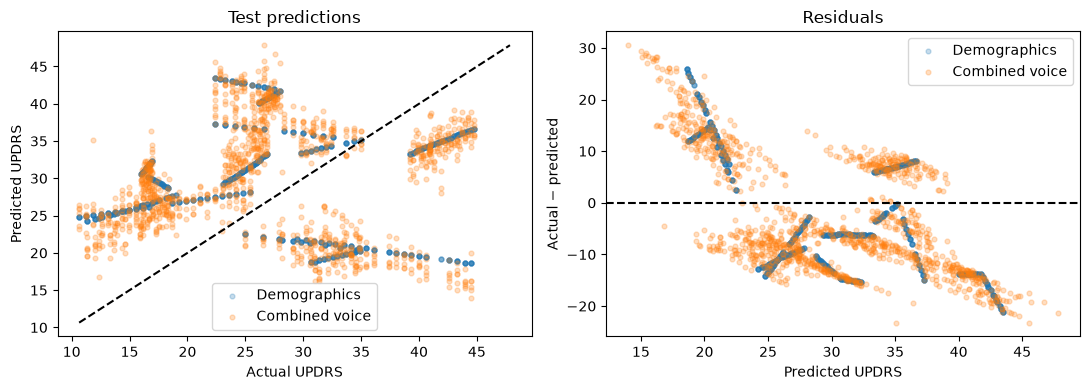

,patient,actual,demographics,combined
575,5,40.910,34.365,35.266
1198,9,23.096,29.301,30.127
1855,14,10.646,24.787,25.408
2671,20,18.362,28.756,28.673
3478,26,30.660,18.719,20.859
3608,27,11.345,24.225,19.533
4039,30,44.469,18.593,16.269
4165,31,29.818,33.438,35.592
5418,40,26.170,40.049,42.978


In [36]:
# Compare the predictions and residuals of both models.
errors = pd.DataFrame({
    "patient": groups_test, "actual": y_test,
    "demographics": predictions["Linear / demographics"],
    "combined": predictions["Linear / combined"],
})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, label in [("demographics", "Demographics"), ("combined", "Combined voice")]:
    errors[name + "_residual"] = errors["actual"] - errors[name]
    errors[name + "_error"] = errors[name + "_residual"].abs()
    axes[0].scatter(errors["actual"], errors[name], alpha=0.25, s=12, label=label)
    axes[1].scatter(errors[name], errors[name + "_residual"], alpha=0.25, s=12, label=label)

values = errors[["actual", "demographics", "combined"]]
limits = [values.min().min(), values.max().max()]
axes[0].plot(limits, limits, "k--")
axes[0].set(xlabel="Actual UPDRS", ylabel="Predicted UPDRS", title="Test predictions")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Predicted UPDRS", ylabel="Actual − predicted", title="Residuals")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

display(errors.groupby("patient").head(1)[
    ["patient", "actual", "demographics", "combined"]
].round(3))

The diagonal shows perfect predictions, and the zero-residual line shows no error. Positive residuals mean underprediction and negative residuals mean overprediction. We plot both models together to see whether voice features bring predictions closer to the actual scores rather than just changing the predictions.

The combined model adds variation around the tighter bands from demographics-only regression, but large errors remain for both models. The extra variation does not consistently move predictions toward the diagonal or residuals toward zero, which matches their similar overall errors. The example rows are the first recording for each patient, not representative averages or selected worst cases; the next table uses all their recordings.

demographics — equal-patient MAE: 10.574 — patients beating baseline: 3
combined — equal-patient MAE: 10.502 — patients beating baseline: 4
Patients helped by adding voice features: 5


,recordings,demographics_MAE,combined_MAE,baseline_MAE,demographics_bias,combined_bias
patient,,,,,,
5,156,6.935,7.176,12.288,6.935,7.176
9,152,6.188,8.109,4.489,-6.188,-8.109
14,136,8.489,8.263,11.549,-8.489,-8.263
20,134,13.612,12.269,12.635,-13.612,-12.269
26,130,10.926,10.482,2.794,10.926,10.422
27,129,10.646,8.412,14.132,-10.646,-8.412
30,126,16.643,17.370,7.344,16.643,17.370
31,130,5.871,7.015,2.931,-5.871,-6.957
40,142,15.854,15.418,3.612,-15.854,-15.418


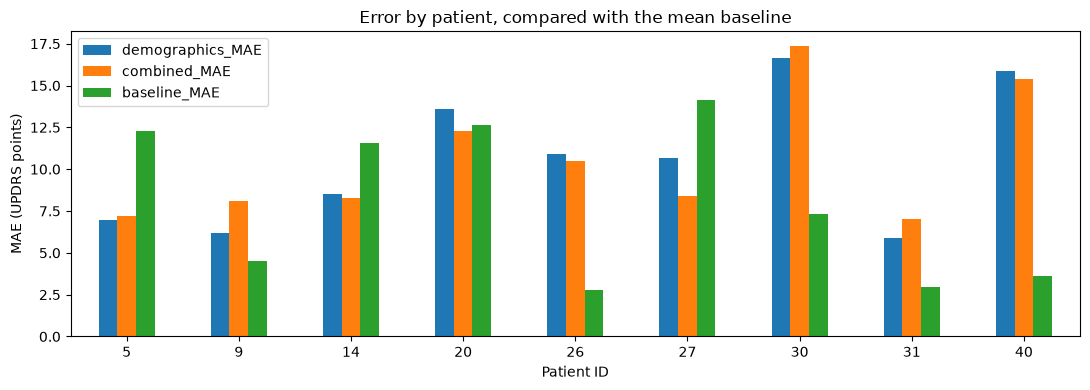

In [37]:
# Check whether voice features help the same patients or only a few.
baseline_name = comparison.loc[["Mean baseline", "Median baseline"], "CV MAE"].idxmin()
errors["baseline_error"] = np.abs(errors["actual"] - predictions[baseline_name])
patient_errors = errors.groupby("patient").agg(
    recordings=("actual", "size"),
    demographics_MAE=("demographics_error", "mean"),
    combined_MAE=("combined_error", "mean"), baseline_MAE=("baseline_error", "mean"),
    demographics_bias=("demographics_residual", "mean"),
    combined_bias=("combined_residual", "mean"),
)
display(patient_errors.round(3))
patient_errors[["demographics_MAE", "combined_MAE", "baseline_MAE"]].plot.bar(figsize=(11, 4))
plt.xlabel("Patient ID")
plt.ylabel("MAE (UPDRS points)")
plt.title(f"Error by patient, compared with the {baseline_name.lower()}")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

for name in ["demographics", "combined"]:
    print(name, "— equal-patient MAE:", round(patient_errors[name + "_MAE"].mean(), 3),
          "— patients beating baseline:", int((patient_errors[name + "_MAE"] < patient_errors["baseline_MAE"]).sum()))
print("Patients helped by adding voice features:",
      int((patient_errors["combined_MAE"] < patient_errors["demographics_MAE"]).sum()))

We compare errors within each patient to check whether adding voice helps broadly or only for a few people. The mean baseline is used here because it had the better validation MAE in this run. Equal-patient MAE gives each patient the same weight instead of weighting each recording equally.

Adding voice features lowered MAE for 5 of 9 patients. Demographics-only regression beat the mean baseline for 3 patients, and combined-feature regression beat it for 4. Equal-patient MAE was 10.502 for the combined model and 10.574 for demographics alone, showing only a small difference. Improvements for some patients were largely offset by worse predictions for others, with large positive and negative patient-level biases remaining.

In [38]:
# Check where in the score range each model makes larger errors.
score_ranges = pd.cut(
    errors["actual"], bins=[-np.inf, 20, 30, 40, np.inf],
    labels=["Below 20", "20 to <30", "30 to <40", "40 or above"], right=False,
)
range_errors = errors.groupby(score_ranges.rename("Actual score"), observed=True).agg(
    recordings=("actual", "size"), patients=("patient", "nunique"),
    demographics_MAE=("demographics_error", "mean"),
    combined_MAE=("combined_error", "mean"), baseline_MAE=("baseline_error", "mean"),
    demographics_bias=("demographics_residual", "mean"),
    combined_bias=("combined_residual", "mean"),
)
display(range_errors.round(3))

,recordings,patients,demographics_MAE,combined_MAE,baseline_MAE,demographics_bias,combined_bias
Actual score,,,,,,,
Below 20,346,3,11.853,10.491,13.684,-11.853,-10.491
20 to <30,441,6,9.622,10.270,4.100,-8.493,-9.117
30 to <40,277,4,9.792,10.044,4.141,8.266,8.006
40 or above,171,2,10.815,11.207,12.741,10.815,11.207


We grouped recordings by actual UPDRS score to see where each model struggled. Adding voice features helped for scores below 20, lowering MAE from 11.853 to 10.491, but made predictions worse in the other three groups. Both models generally predicted low scores too high and high scores too low.

Both models beat the mean baseline at the low and high ends, but lost to it between 20 and 40, where most test recordings fell. Each group contains only a few patients, so these differences may also reflect which patients were in each group.

### What we learned

The feature-engineering results were mixed. Taking natural logs reduced skewness, but ordinary linear regression's CV MAE increased from 9.651 to 9.881. Combining the logged Jitter and Shimmer measures improved it to 9.352, while demographics alone still performed better at 8.832. The initial nonlinear models did not improve on demographics-only regression.

The two baseline-change features captured within-patient voice history without using previous clinical scores. They increased linear regression's CV MAE from 9.352 to 9.458 and helped in only 2 of 5 folds. Lasso with fixed `alpha=1` reduced the 12-feature model's MAE to 8.660, improving 4 of 5 folds relative to ordinary linear regression on the same inputs. However, Lasso without the changes was slightly better at 8.651, and demographics-only Lasso was best at 8.632. Regularization helped, but the voice and change features did not demonstrate an added average validation benefit.

The improvement from demographics-only linear regression to Lasso was about 0.200 UPDRS points, small compared with variation between patient folds. The wider parameter searches sometimes hurt outer-fold MAE, showing that tuning does not guarantee better generalization with this small patient sample. These follow-up results are exploratory cross-validation findings, not a new independent test result.

On the nine test patients, the two original linear models had MAEs of 10.450 and 10.411, both worse than the training-mean and training-median baselines. Adding voice helped some patients and hurt others. We do not interpret these experiments as proving that voice contains no useful severity information; they show limited generalization for the features, models, and evaluation setups we tried.

Although the dataset has thousands of recordings, only 33 patients were available for training. More diverse patients, independently measured follow-up UPDRS scores instead of interpolated labels, and a new evaluation cohort would help assess whether these findings transfer. Since follow-up experiments were proposed after inspecting earlier test results, the existing test patients should not be treated as a fresh confirmation of those discoveries.

## Appendix: checks for temporal preprocessing

These checks verify session averaging, zero baseline changes, row-order independence, use of each validation patient's own baseline, exclusion of future-session information, and rejection of UPDRS columns. They also verify that the 10-feature control matches the first 10 outputs of the augmented transformer.

In [39]:
import unittest

import numpy as np
import pandas as pd
from pandas.testing import assert_frame_equal
from sklearn.base import clone



class BaselineVoiceFeaturesTests(unittest.TestCase):
    def setUp(self):
        self.X = pd.DataFrame({
            "subject#": [1] * 4 + [2] * 4,
            "age": [60] * 4 + [70] * 4,
            "sex": [0] * 4 + [1] * 4,
            "test_time": [0, 0, 10, 20, 5, 5, 15, 25],
            "Jitter(%)": np.exp(np.arange(8) / 10),
            "Jitter:PPQ5": np.exp(np.arange(8) / 5),
            "Shimmer": np.exp(-np.arange(8) / 8),
            "Shimmer:APQ3": np.exp(np.arange(8) / 7),
            "NHR": np.full(8, 0.02),
            "HNR": np.arange(8) + 10,
            "RPDE": np.full(8, 0.5),
            "DFA": np.full(8, 0.6),
            "PPE": np.full(8, 0.2),
        }, index=np.arange(100, 108))
        self.change_columns = [
            "Jitter_change_from_baseline", "Shimmer_change_from_baseline"
        ]

    def test_session_mean_changes_and_zero_baseline(self):
        result = BaselineVoiceFeatures().fit_transform(self.X)
        self.assertEqual(result.shape, (8, 12))
        np.testing.assert_array_equal(result.iloc[[0, 1, 4, 5]][self.change_columns], 0)
        for position, baseline in [(2, [0, 1]), (6, [4, 5])]:
            expected = (
                result.iloc[position][["Jitter_combined", "Shimmer_combined"]].to_numpy()
                - result.iloc[baseline][["Jitter_combined", "Shimmer_combined"]].mean().to_numpy()
            )
            np.testing.assert_allclose(result.iloc[position][self.change_columns], expected)
        self.assertNotIn("subject#", result)
        self.assertNotIn("total_UPDRS", result)

    def test_row_order_does_not_choose_baseline(self):
        transformer = BaselineVoiceFeatures().fit(self.X)
        result = transformer.transform(self.X)
        shuffled = self.X.sample(frac=1, random_state=42)
        assert_frame_equal(result, transformer.transform(shuffled).loc[self.X.index])

    def test_future_sessions_do_not_change_earlier_features(self):
        transformer = BaselineVoiceFeatures().fit(self.X)
        result = transformer.transform(self.X)
        prefix = self.X.drop(index=[103, 107])
        assert_frame_equal(result.loc[prefix.index], transformer.transform(prefix))
        changed_future = self.X.copy()
        changed_future.loc[[103, 107], ["Jitter(%)", "Shimmer"]] *= 100
        assert_frame_equal(
            result.loc[prefix.index], transformer.transform(changed_future).loc[prefix.index]
        )

    def test_validation_patient_uses_own_baseline_without_refitting(self):
        train, validation = self.X.iloc[:4], self.X.iloc[4:]
        transformer = BaselineVoiceFeatures().fit(train)
        expected_mean = np.log(train[transformer.jitter_columns_]).mean().to_numpy()
        result = transformer.transform(validation)
        np.testing.assert_allclose(transformer.jitter_scaler_.mean_, expected_mean)
        np.testing.assert_array_equal(result.iloc[:2][self.change_columns], 0)
        self.assertTrue(np.isfinite(result.to_numpy()).all())

    def test_control_has_identical_original_features_and_clone_works(self):
        changes = BaselineVoiceFeatures().fit_transform(self.X)
        control = clone(BaselineVoiceFeatures(include_changes=False)).fit_transform(self.X)
        self.assertEqual(control.shape[1], 10)
        assert_frame_equal(control, changes.drop(columns=self.change_columns))

    def test_targets_are_rejected(self):
        with self.assertRaisesRegex(ValueError, "Exclude UPDRS"):
            BaselineVoiceFeatures().fit(self.X.assign(total_UPDRS=20))


import sys
voice_feature_checks = unittest.defaultTestLoader.loadTestsFromTestCase(BaselineVoiceFeaturesTests)
voice_feature_check_result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(voice_feature_checks)
assert voice_feature_check_result.wasSuccessful(), "Temporal preprocessing checks failed."

test_control_has_identical_original_features_and_clone_works (__main__.BaselineVoiceFeaturesTests.test_control_has_identical_original_features_and_clone_works) ... ok
test_future_sessions_do_not_change_earlier_features (__main__.BaselineVoiceFeaturesTests.test_future_sessions_do_not_change_earlier_features) ... ok
test_row_order_does_not_choose_baseline (__main__.BaselineVoiceFeaturesTests.test_row_order_does_not_choose_baseline) ... ok
test_session_mean_changes_and_zero_baseline (__main__.BaselineVoiceFeaturesTests.test_session_mean_changes_and_zero_baseline) ... ok
test_targets_are_rejected (__main__.BaselineVoiceFeaturesTests.test_targets_are_rejected) ... ok
test_validation_patient_uses_own_baseline_without_refitting (__main__.BaselineVoiceFeaturesTests.test_validation_patient_uses_own_baseline_without_refitting) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.034s

OK
